<a href="https://colab.research.google.com/github/irankkk/cpp-practice-2026/blob/main/HW5/kalinichenko_i_v.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
!apt-get update -qq
!apt-get install -y g++ libopencv-dev libcurl4-openssl-dev

W: Skipping acquire of configured file 'main/source/Sources' as repository 'https://r2u.stat.illinois.edu/ubuntu noble InRelease' does not seem to provide it (sources.list entry misspelt?)
Reading package lists... Done
Building dependency tree... Done
Reading state information... Done
g++ is already the newest version (4:13.2.0-7ubuntu1).
g++ set to manually installed.
libcurl4-openssl-dev is already the newest version (8.5.0-2ubuntu10.16).
The following additional packages will be installed:
  at-spi2-common at-spi2-core gsettings-desktop-schemas
  gstreamer1.0-plugins-base libatk-bridge2.0-0t64 libatk1.0-0t64
  libatspi2.0-0t64 libavcodec-dev libavformat-dev libavutil-dev libcdparanoia0
  libcharls2 libdc1394-dev libdouble-conversion3 libevdev2 libexif-dev
  libexif-doc libexif12 libgdcm-dev libgdcm3.0t64 libgl2ps1.4 libglew2.2
  libgphoto2-6t64 libgphoto2-dev libgphoto2-l10n libgphoto2-port12t64
  libgstreamer-plugins-base1.0-0 libgtk-3-0t64 libgtk-3-bin libgtk-3-common
  libgudev-1

In [9]:
%%writefile main.cpp
#include <iostream>
#include <vector>
#include <string>
#include <opencv2/opencv.hpp>
#include <curl/curl.h>

size_t WriteMemoryCallback(void* contents, size_t size, size_t nmemb, void* userp) {
    size_t realsize = size * nmemb;
    auto* mem = static_cast<std::vector<uchar>*>(userp);
    auto* ptr = static_cast<uchar*>(contents);
    mem->insert(mem->end(), ptr, ptr + realsize);
    return realsize;
}

int main() {
    const char* image_url = "https://upload.wikimedia.org/wikipedia/commons/4/40/Children_at_school_%288720604364%29.jpg";
    CURL* curl_handle;
    CURLcode res;
    std::vector<uchar> image_data;

    curl_global_init(CURL_GLOBAL_DEFAULT);
    curl_handle = curl_easy_init();

    if(curl_handle) {
        curl_easy_setopt(curl_handle, CURLOPT_URL, image_url);
        curl_easy_setopt(curl_handle, CURLOPT_WRITEFUNCTION, WriteMemoryCallback);
        curl_easy_setopt(curl_handle, CURLOPT_WRITEDATA, &image_data);
        curl_easy_setopt(curl_handle, CURLOPT_USERAGENT, "libcurl-agent/1.0");
        curl_easy_setopt(curl_handle, CURLOPT_FOLLOWLOCATION, 1L);

        res = curl_easy_perform(curl_handle);

        if(res != CURLE_OK) {
            std::cerr << "curl_easy_perform() failed: " << curl_easy_strerror(res) << std::endl;
            curl_easy_cleanup(curl_handle);
            curl_global_cleanup();
            return 1;
        }
        curl_easy_cleanup(curl_handle);
    }
    curl_global_cleanup();

    std::cout << "Downloaded " << image_data.size() << " bytes." << std::endl;

    cv::Mat image = cv::imdecode(image_data, cv::IMREAD_COLOR);

    if (image.empty()) {
        std::cerr << "Could not decode image!" << std::endl;
        return 1;
    }

    std::cout << "Image decoded successfully: " << image.cols << "x" << image.rows << std::endl;

    // Сохраняем оригинал, чтобы потом показать его в Python
    cv::imwrite("original_output.jpg", image);

    // Обработка: перевод в оттенки серого
    cv::Mat gray;
    cv::cvtColor(image, gray, cv::COLOR_BGR2GRAY);

    cv::imwrite("gray_output.jpg", gray);
    std::cout << "Images saved as original_output.jpg and gray_output.jpg" << std::endl;

    return 0;
}

Overwriting main.cpp


In [10]:
!g++ main.cpp -o main $(pkg-config --cflags --libs opencv4 libcurl) -std=c++17
!./main

Downloaded 1169519 bytes.
Image decoded successfully: 1697x1131
Images saved as original_output.jpg and gray_output.jpg


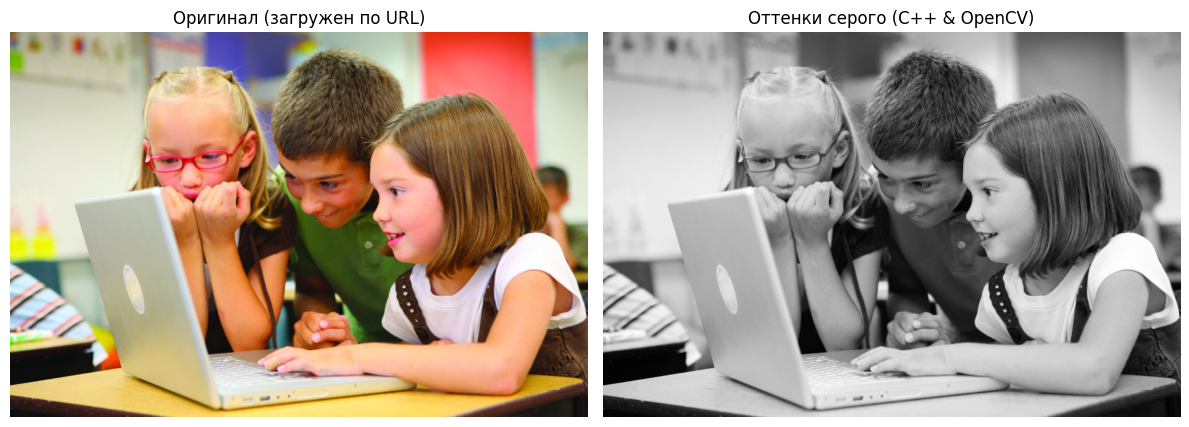

In [11]:
import matplotlib.pyplot as plt
import cv2

# Загружаем оба сохранённых изображения
img_original = cv2.imread('original_output.jpg')
img_gray = cv2.imread('gray_output.jpg', cv2.IMREAD_GRAYSCALE)

if img_original is not None and img_gray is not None:
    # Конвертируем оригинал из BGR (OpenCV) в RGB (Matplotlib)
    img_original_rgb = cv2.cvtColor(img_original, cv2.COLOR_BGR2RGB)

    fig, axes = plt.subplots(1, 2, figsize=(12, 6))

    axes[0].imshow(img_original_rgb)
    axes[0].set_title('Оригинал (загружен по URL)')
    axes[0].axis('off')

    axes[1].imshow(img_gray, cmap='gray')
    axes[1].set_title('Оттенки серого (C++ & OpenCV)')
    axes[1].axis('off')

    plt.tight_layout()
    plt.show()
else:
    print("Не удалось загрузить одно из изображений.")

In [14]:
%%writefile detect_faces.cpp
#include <iostream>
#include <vector>
#include <string>
#include <opencv2/opencv.hpp>
#include <opencv2/objdetect.hpp>
#include <curl/curl.h>

size_t WriteMemoryCallback(void* contents, size_t size, size_t nmemb, void* userp) {
    size_t realsize = size * nmemb;
    auto* mem = static_cast<std::vector<uchar>*>(userp);
    auto* ptr = static_cast<uchar*>(contents);
    mem->insert(mem->end(), ptr, ptr + realsize);
    return realsize;
}

std::vector<uchar> download(const std::string& url) {
    std::vector<uchar> data;
    CURL* curl = curl_easy_init();
    if (curl) {
        curl_easy_setopt(curl, CURLOPT_URL, url.c_str());
        curl_easy_setopt(curl, CURLOPT_WRITEFUNCTION, WriteMemoryCallback);
        curl_easy_setopt(curl, CURLOPT_WRITEDATA, &data);
        curl_easy_setopt(curl, CURLOPT_FOLLOWLOCATION, 1L);
        curl_easy_setopt(curl, CURLOPT_USERAGENT, "libcurl-agent/1.0");
        curl_easy_perform(curl);
        curl_easy_cleanup(curl);
    }
    return data;
}

// Универсальная загрузка: URL или локальный файл
cv::Mat loadImage(const std::string& source) {
    if (source.rfind("http", 0) == 0) {
        auto bytes = download(source);
        return cv::imdecode(bytes, cv::IMREAD_COLOR);
    }
    return cv::imread(source);
}

int main(int argc, char** argv) {
    // Источник: аргумент командной строки, иначе — URL по умолчанию
    std::string source = (argc > 1) ? argv[1]
    : "https://upload.wikimedia.org/wikipedia/commons/4/40/Children_at_school_%288720604364%29.jpg";

    std::cout << "Loading: " << source << std::endl;
    cv::Mat image = loadImage(source);
    if (image.empty()) {
        std::cerr << "Failed to load image from: " << source << std::endl;
        return 1;
    }
    std::cout << "Image: " << image.cols << "x" << image.rows << std::endl;

    // Каскады
    cv::CascadeClassifier face_cascade, eye_cascade;
    if (!face_cascade.load("/usr/share/opencv4/haarcascades/haarcascade_frontalface_default.xml") ||
        !eye_cascade.load("/usr/share/opencv4/haarcascades/haarcascade_eye.xml")) {
        std::cerr << "Cannot load cascades" << std::endl;
        return 1;
    }

    // Подготовка
    cv::Mat gray;
    cv::cvtColor(image, gray, cv::COLOR_BGR2GRAY);
    cv::equalizeHist(gray, gray);

    // Детекция лиц — вернёт ВСЕ найденные лица
    std::vector<cv::Rect> faces;
    face_cascade.detectMultiScale(
        gray, faces,
        /*scaleFactor*/  1.05,   // чуть меньше, чем 1.1 — ищем тщательнее (для групповых фото)
        /*minNeighbors*/ 5,
        /*flags*/        0,
        /*minSize*/      cv::Size(20, 20)   // маленькие лица тоже ловим
    );

    std::cout << "Detected faces: " << faces.size() << std::endl;

    // Рисуем рамку + номер для каждого лица
    int idx = 0;
    for (const auto& face : faces) {
        ++idx;
        cv::rectangle(image, face, cv::Scalar(0, 255, 0), 2);

        // Подпись "Face N" над рамкой
        std::string label = "Face " + std::to_string(idx);
        int baseline = 0;
        cv::Size text_size = cv::getTextSize(label, cv::FONT_HERSHEY_SIMPLEX, 0.6, 2, &baseline);
        cv::Point text_org(face.x, face.y - 5);
        if (text_org.y < text_size.height) text_org.y = face.y + text_size.height + 5;

        cv::rectangle(image,
                      cv::Point(text_org.x, text_org.y - text_size.height - 2),
                      cv::Point(text_org.x + text_size.width, text_org.y + 2),
                      cv::Scalar(0, 255, 0), cv::FILLED);
        cv::putText(image, label, text_org, cv::FONT_HERSHEY_SIMPLEX, 0.6,
                    cv::Scalar(0, 0, 0), 2);

        // Глаза ищем только в верхних 60% лица (там они и находятся)
        cv::Mat face_roi_gray  = gray(face);
        cv::Mat face_roi_gray_top = face_roi_gray(cv::Rect(0, 0, face.width, face.height * 6 / 10));

        std::vector<cv::Rect> eyes;
        eye_cascade.detectMultiScale(face_roi_gray_top, eyes, 1.1, 10);
        for (const auto& eye : eyes) {
            cv::Rect eye_abs(face.x + eye.x, face.y + eye.y, eye.width, eye.height);
            cv::rectangle(image, eye_abs, cv::Scalar(255, 0, 0), 2);
        }
    }

    cv::imwrite("faces_detected.jpg", image);
    std::cout << "Result saved: faces_detected.jpg" << std::endl;

    if (faces.empty()) {
        std::cerr << "No faces detected. Try another image or lower minNeighbors." << std::endl;
        return 2;
    }
    return 0;
}

Overwriting detect_faces.cpp


In [15]:
!g++ detect_faces.cpp -o detect_faces $(pkg-config --cflags --libs opencv4 libcurl) -std=c++17
!./detect_faces

Loading: https://upload.wikimedia.org/wikipedia/commons/4/40/Children_at_school_%288720604364%29.jpg
Image: 1697x1131
Detected faces: 1
Result saved: faces_detected.jpg


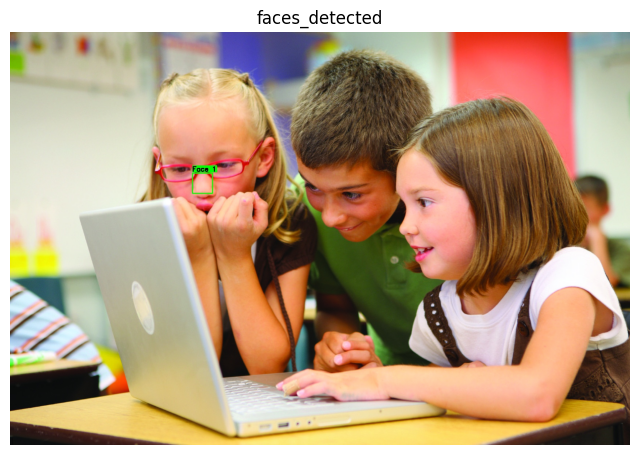

In [16]:
import matplotlib.pyplot as plt
import cv2

img = cv2.imread('faces_detected.jpg')

if img is not None:
    img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

    plt.figure(figsize=(8, 8))
    plt.imshow(img_rgb)
    plt.title('faces_detected')
    plt.axis('off')
    plt.show()
else:
    print("Не удалось загрузить изображение.")

ВЫВОД
Метод. В работе использован каскадный классификатор Хаара из OpenCV. Он ищет объект по признакам Хаара простым контрастным шаблонам. Признаки объединены в 25 стадий каскада: окно проходит эти стадии и отбрасывается при первой неудаче, что обеспечивает высокую скорость. Функция detectMultiScale строит пирамиду масштабов (scaleFactor=1.05), скользит окном по изображению и оставляет рамки,, игнорируя объекты меньше 20×20 (minSize).

Эксперимент: На фото дети за ноутбуком (размер фото 1697×1131) каскад обнаружил только одно лицо это девочка в очках слева в анфасе. Лица мальчика (полуоборот) и девочки (профиль) пропущены и размытый ребёнок на фоне не обнаружен.

Причина: Каскад frontalface_default обучен исключительно на фронтальных лицах. При повороте головы меняются контрасты и геометрия лица, поэтому признаки Хаара не совпадают с выученными, и окно отбрасывается на одной из ранних стадий. То есть метод полностью зависит от ракурса.